In [4]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: C:\Users\LaptopUser\AppData\Local\Programs\Python\Python312\python.exe -m pip install --upgrade pip


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
df = pd.read_csv("customer_segmentation.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


In [4]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [5]:
df.isnull().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [6]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [7]:
print(df['Gender'].value_counts())

Gender
Female    112
Male       88
Name: count, dtype: int64


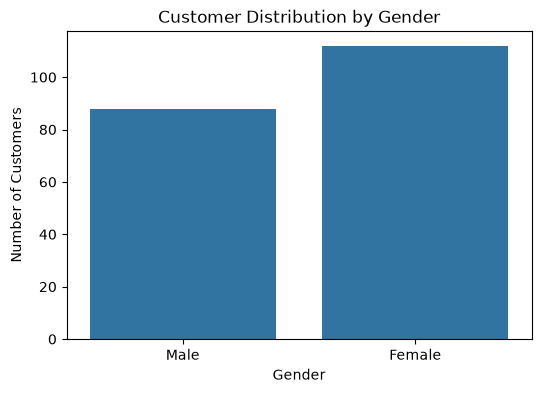

In [8]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x='Gender')

plt.title('Customer Distribution by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Customers')

plt.savefig('visualization_1_gender_distribution.png',
            dpi=300, bbox_inches='tight')

plt.show()

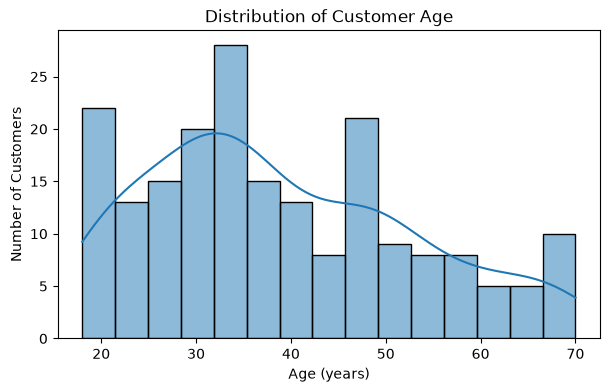

In [9]:
plt.figure(figsize=(7, 4))

sns.histplot(data=df, x='Age', bins=15, kde=True)

plt.title('Distribution of Customer Age')
plt.xlabel('Age (years)')
plt.ylabel('Number of Customers')

plt.savefig('visualization_2_age_distribution.png',
            dpi=300, bbox_inches='tight')

plt.show()

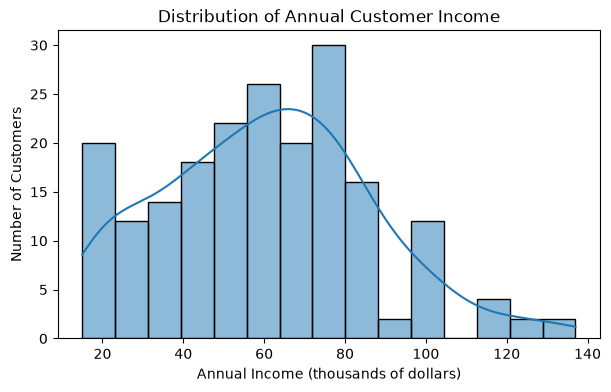

In [10]:
plt.figure(figsize=(7, 4))

sns.histplot(data=df, x='Annual Income (k$)',
             bins=15, kde=True)

plt.title('Distribution of Annual Customer Income')
plt.xlabel('Annual Income (thousands of dollars)')
plt.ylabel('Number of Customers')

plt.savefig('visualization_3_income_distribution.png',
            dpi=300, bbox_inches='tight')

plt.show()

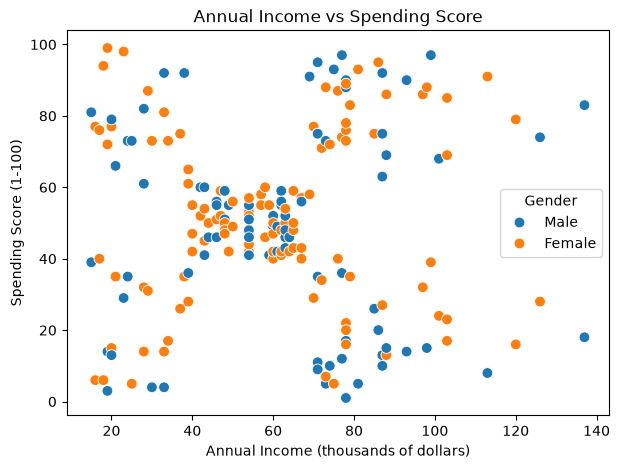

In [11]:
plt.figure(figsize=(7, 5))

sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Gender',
    s=60
)

plt.title('Annual Income vs Spending Score')
plt.xlabel('Annual Income (thousands of dollars)')
plt.ylabel('Spending Score (1-100)')
plt.legend(title='Gender')

plt.savefig('visualization_4_income_vs_spending.png',
            dpi=300, bbox_inches='tight')

plt.show()

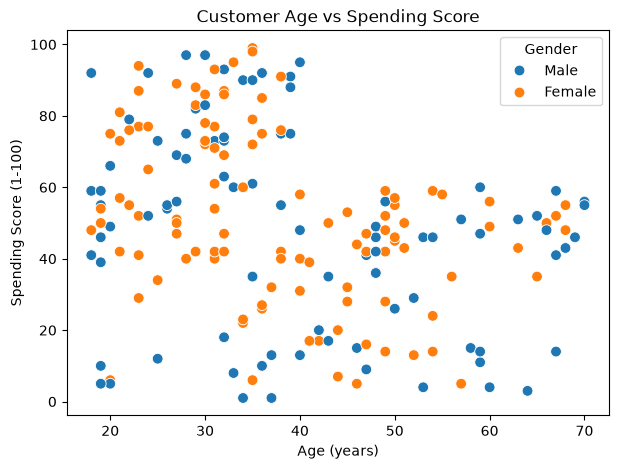

In [12]:
plt.figure(figsize=(7, 5))

sns.scatterplot(
    data=df,
    x='Age',
    y='Spending Score (1-100)',
    hue='Gender',
    s=60
)

plt.title('Customer Age vs Spending Score')
plt.xlabel('Age (years)')
plt.ylabel('Spending Score (1-100)')
plt.legend(title='Gender')

plt.savefig('visualization_5_age_vs_spending.png',
            dpi=300, bbox_inches='tight')

plt.show()

In [13]:
# Select features for clustering

X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

print("Selected features:")
print(X.head())

print("\nFeature shape:", X.shape)

Selected features:
   Annual Income (k$)  Spending Score (1-100)
0                  15                      39
1                  15                      81
2                  16                       6
3                  16                      77
4                  17                      40

Feature shape: (200, 2)


In [14]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Standardization completed!")
print("Scaled data shape:", X_scaled.shape)

print("\nFirst five scaled observations:")
print(X_scaled[:5])

Standardization completed!
Scaled data shape: (200, 2)

First five scaled observations:
[[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]


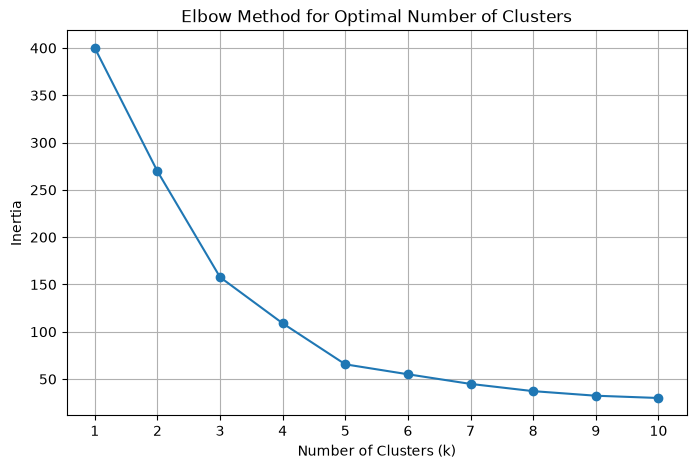

In [15]:
inertia = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(range(1, 11), inertia, marker='o')

plt.title('Elbow Method for Optimal Number of Clusters')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.xticks(range(1, 11))
plt.grid(True)

plt.savefig('visualization_6_elbow_method.png',
            dpi=300, bbox_inches='tight')

plt.show()

In [16]:
silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

    print(f"k = {k}, Silhouette Score = {score:.4f}")

k = 2, Silhouette Score = 0.3213
k = 3, Silhouette Score = 0.4666
k = 4, Silhouette Score = 0.4939
k = 5, Silhouette Score = 0.5547
k = 6, Silhouette Score = 0.5399
k = 7, Silhouette Score = 0.5281
k = 8, Silhouette Score = 0.4552
k = 9, Silhouette Score = 0.4571
k = 10, Silhouette Score = 0.4432


In [17]:
# Apply K-Means clustering with 5 clusters

kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

df['Cluster'] = kmeans.fit_predict(X_scaled)

print("K-Means clustering completed!")
print("\nCustomer distribution across clusters:")
print(df['Cluster'].value_counts().sort_index())

K-Means clustering completed!

Customer distribution across clusters:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


In [18]:
print("Final Silhouette Score:",
      round(silhouette_score(X_scaled, df['Cluster']), 4))

Final Silhouette Score: 0.5547


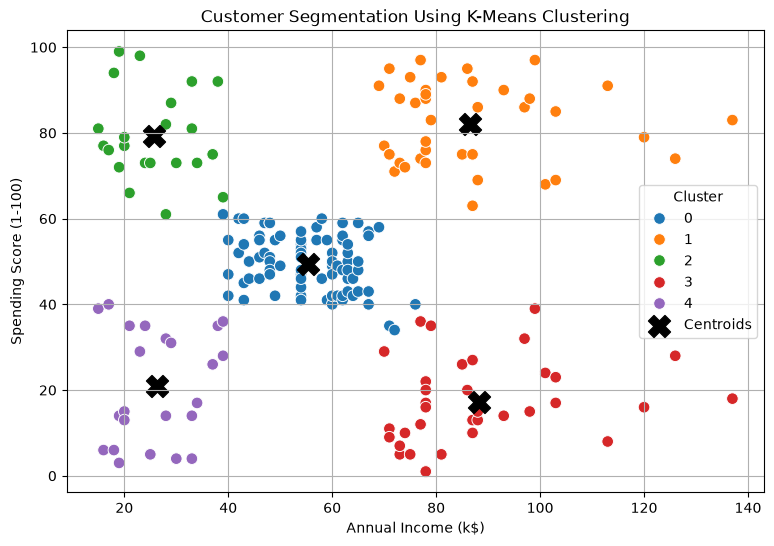

In [19]:
# Convert cluster centers back to original values
centers_scaled = kmeans.cluster_centers_
centers_original = scaler.inverse_transform(centers_scaled)

# Plot customer clusters
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Cluster',
    palette='tab10',
    s=70
)

# Plot cluster centroids
plt.scatter(
    centers_original[:, 0],
    centers_original[:, 1],
    s=250,
    marker='X',
    color='black',
    label='Centroids'
)

plt.title('Customer Segmentation Using K-Means Clustering')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(title='Cluster')
plt.grid(True)

plt.savefig(
    'visualization_8_kmeans_customer_clusters.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [20]:
cluster_summary = df.groupby('Cluster').agg(
    Customer_Count=('CustomerID', 'count'),
    Average_Age=('Age', 'mean'),
    Average_Annual_Income=('Annual Income (k$)', 'mean'),
    Average_Spending_Score=('Spending Score (1-100)', 'mean')
).round(2)

print("Customer Profile for Each Cluster:")
print(cluster_summary)

Customer Profile for Each Cluster:
         Customer_Count  Average_Age  Average_Annual_Income  \
Cluster                                                       
0                    81        42.72                  55.30   
1                    39        32.69                  86.54   
2                    22        25.27                  25.73   
3                    35        41.11                  88.20   
4                    23        45.22                  26.30   

         Average_Spending_Score  
Cluster                          
0                         49.52  
1                         82.13  
2                         79.36  
3                         17.11  
4                         20.91  


In [21]:
gender_profile = pd.crosstab(
    df['Cluster'],
    df['Gender'],
    normalize='index'
).round(2) * 100

print("Gender Distribution Within Each Cluster (%):")
print(gender_profile)

Gender Distribution Within Each Cluster (%):
Gender   Female  Male
Cluster              
0          59.0  41.0
1          54.0  46.0
2          59.0  41.0
3          46.0  54.0
4          61.0  39.0


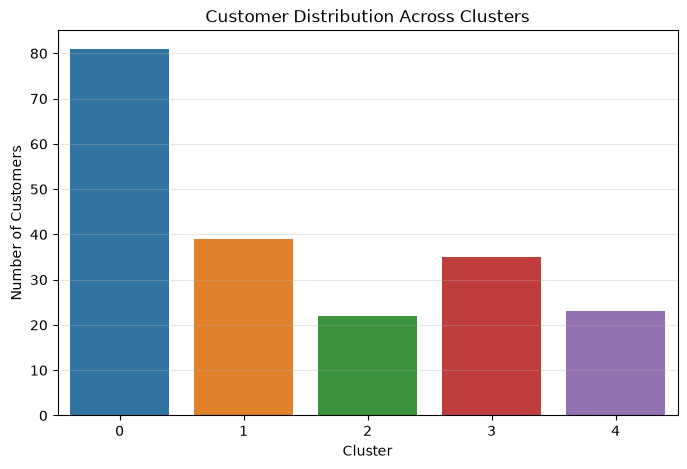

In [22]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Cluster',
    hue='Cluster',
    palette='tab10',
    legend=False
)

plt.title('Customer Distribution Across Clusters')
plt.xlabel('Cluster')
plt.ylabel('Number of Customers')
plt.xticks(range(5))
plt.grid(axis='y', alpha=0.3)

plt.savefig(
    'visualization_9_cluster_distribution.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [23]:
print("FINAL MODEL EVALUATION")
print("----------------------")

print("Algorithm: K-Means Clustering")
print("Number of Clusters:", 5)
print("Total Customers:", len(df))

print(
    "Silhouette Score:",
    round(silhouette_score(X_scaled, df['Cluster']), 4)
)

print("\nCluster Sizes:")
print(df['Cluster'].value_counts().sort_index())

print("\nCluster Centres (Original Scale):")
print(pd.DataFrame(
    centers_original,
    columns=['Annual Income (k$)', 'Spending Score']
).round(2))

FINAL MODEL EVALUATION
----------------------
Algorithm: K-Means Clustering
Number of Clusters: 5
Total Customers: 200
Silhouette Score: 0.5547

Cluster Sizes:
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64

Cluster Centres (Original Scale):
   Annual Income (k$)  Spending Score
0               55.30           49.52
1               86.54           82.13
2               25.73           79.36
3               88.20           17.11
4               26.30           20.91


In [26]:
from docx import Document
from docx.shared import Inches, Pt
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.enum.table import WD_TABLE_ALIGNMENT
import os

# Check that all nine visualizations are available
image_files = [
    f'visualization_{i}_' + name + '.png'
    for i, name in [
        (1, 'gender_distribution'),
        (2, 'age_distribution'),
        (3, 'income_distribution'),
        (4, 'income_vs_spending'),
        (5, 'age_vs_spending'),
        (6, 'elbow_method'),
        (7, 'silhouette_scores'),
        (8, 'kmeans_customer_clusters'),
        (9, 'cluster_distribution')
    ]
]

for file in image_files:
    print(file, "✓" if os.path.exists(file) else "MISSING")

visualization_1_gender_distribution.png ✓
visualization_2_age_distribution.png ✓
visualization_3_income_distribution.png ✓
visualization_4_income_vs_spending.png ✓
visualization_5_age_vs_spending.png ✓
visualization_6_elbow_method.png ✓
visualization_7_silhouette_scores.png ✓
visualization_8_kmeans_customer_clusters.png ✓
visualization_9_cluster_distribution.png ✓


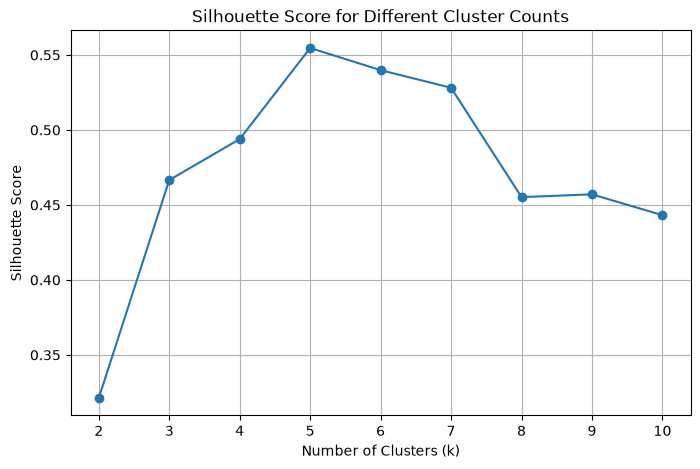

In [25]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker='o'
)

plt.title('Silhouette Score for Different Cluster Counts')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.xticks(range(2, 11))
plt.grid(True)

plt.savefig(
    'visualization_7_silhouette_scores.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [27]:

from docx import Document
from docx.shared import Inches, Pt
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.enum.table import WD_TABLE_ALIGNMENT
from docx.oxml import OxmlElement
from docx.oxml.ns import qn
import os

doc = Document()

# Page margins
for section in doc.sections:
    section.top_margin = Inches(0.7)
    section.bottom_margin = Inches(0.7)
    section.left_margin = Inches(0.8)
    section.right_margin = Inches(0.8)

# Default font
styles = doc.styles
styles['Normal'].font.name = 'Arial'
styles['Normal'].font.size = Pt(10)

# Helper functions
def add_heading(text, level=1):
    doc.add_heading(text, level=level)

def add_paragraph(text):
    doc.add_paragraph(text)

def add_image(filename, caption):
    if os.path.exists(filename):
        p = doc.add_paragraph()
        p.alignment = WD_ALIGN_PARAGRAPH.CENTER
        p.add_run().add_picture(filename, width=Inches(5.8))
        cap = doc.add_paragraph(caption)
        cap.alignment = WD_ALIGN_PARAGRAPH.CENTER
        cap.runs[0].italic = True
        cap.runs[0].font.size = Pt(9)

def add_table(headers, rows):
    table = doc.add_table(rows=1, cols=len(headers))
    table.style = 'Table Grid'
    table.alignment = WD_TABLE_ALIGNMENT.CENTER
    for i, h in enumerate(headers):
        table.rows[0].cells[i].text = str(h)
    for row in rows:
        cells = table.add_row().cells
        for i, value in enumerate(row):
            cells[i].text = str(value)
    return table

# Title page
p = doc.add_paragraph()
p.alignment = WD_ALIGN_PARAGRAPH.CENTER
r = p.add_run('CUSTOMER SEGMENTATION\nUSING K-MEANS CLUSTERING')
r.bold = True
r.font.size = Pt(22)

p = doc.add_paragraph()
p.alignment = WD_ALIGN_PARAGRAPH.CENTER
r = p.add_run('\nWEEK 3 PROJECT REPORT\nUnsupervised Learning and Clustering Analysis')
r.font.size = Pt(14)

p = doc.add_paragraph()
p.alignment = WD_ALIGN_PARAGRAPH.CENTER
p.add_run('\nVirtual Data Science with Python Internship\n')
p.add_run('Tools: Python | Pandas | NumPy | Matplotlib | Seaborn | Scikit-learn')

doc.add_page_break()

# 1. Introduction
add_heading('1. Introduction')
add_paragraph(
    'Customer segmentation is the process of dividing customers into groups '
    'based on shared characteristics and behaviour. It helps businesses '
    'understand different customer groups and develop more focused marketing '
    'strategies. This project applies K-Means clustering, an unsupervised '
    'machine learning algorithm, to segment customers using annual income '
    'and spending score.'
)

# 2. Objectives
add_heading('2. Project Objectives')
for item in [
    'Explore and understand the customer dataset.',
    'Perform data inspection and preprocessing.',
    'Apply K-Means clustering to identify customer segments.',
    'Determine a suitable number of clusters using the Elbow Method and Silhouette Score.',
    'Visualize and interpret the resulting customer groups.',
    'Discuss possible business applications and limitations.'
]:
    doc.add_paragraph(item, style='List Bullet')

# 3. Dataset
add_heading('3. Dataset Description')
add_paragraph(
    'The Mall Customer Segmentation dataset was obtained from Kaggle. '
    'It contains 200 customer records and five attributes: CustomerID, '
    'Gender, Age, Annual Income (k$), and Spending Score (1-100). '
    'The spending score represents a score assigned to customers based '
    'on their spending behaviour.'
)
add_table(
    ['Attribute', 'Description'],
    [
        ['CustomerID', 'Unique customer identifier'],
        ['Gender', 'Customer gender'],
        ['Age', 'Customer age in years'],
        ['Annual Income (k$)', 'Annual income in thousands of dollars'],
        ['Spending Score (1-100)', 'Spending score ranging from 1 to 100']
    ]
)

# 4. EDA
add_heading('4. Exploratory Data Analysis')
add_paragraph(
    'The dataset was examined using Pandas functions such as info(), '
    'describe(), isnull().sum(), and duplicated(). The dataset contained '
    '200 rows and five columns. No missing values or duplicate records '
    'were identified. The gender distribution consisted of 112 female '
    'customers and 88 male customers.'
)
add_paragraph(
    'The average customer age was 38.85 years. The mean annual income '
    'was 60.56 thousand dollars, while the mean spending score was 50.20.'
)

add_heading('4.1 Gender Distribution', 2)
add_image('visualization_1_gender_distribution.png',
          'Figure 1: Distribution of customers by gender.')

add_heading('4.2 Age Distribution', 2)
add_image('visualization_2_age_distribution.png',
          'Figure 2: Age distribution of customers.')

add_heading('4.3 Annual Income Distribution', 2)
add_image('visualization_3_income_distribution.png',
          'Figure 3: Distribution of annual income.')

add_heading('4.4 Income and Spending Relationship', 2)
add_image('visualization_4_income_vs_spending.png',
          'Figure 4: Relationship between annual income and spending score.')

add_heading('4.5 Age and Spending Relationship', 2)
add_image('visualization_5_age_vs_spending.png',
          'Figure 5: Relationship between customer age and spending score.')

# 5. Preprocessing
add_heading('5. Data Preprocessing and Feature Selection')
add_paragraph(
    'CustomerID was excluded because it is an identifier and does not '
    'represent customer behaviour. Gender and Age were retained for '
    'exploratory analysis and later cluster profiling, but were not used '
    'as input features in the initial clustering model.'
)
add_paragraph(
    'Annual Income (k$) and Spending Score (1-100) were selected as the '
    'two clustering features. StandardScaler was applied to standardize '
    'both features before clustering. Standardization places the features '
    'on comparable scales and prevents differences in their numerical '
    'ranges from disproportionately influencing distance calculations.'
)

# 6. Methodology
add_heading('6. Clustering Methodology')
add_paragraph(
    'K-Means is an unsupervised learning algorithm that partitions data '
    'into a predefined number of clusters. It assigns observations to '
    'the nearest cluster centroid and iteratively updates the centroids '
    'to reduce within-cluster variation.'
)
add_paragraph(
    'The model was implemented using Scikit-learn. The random_state '
    'parameter was set to 42 for reproducibility, and n_init was set '
    'to 10 to run the algorithm with multiple centroid initializations.'
)

add_heading('6.1 Elbow Method', 2)
add_paragraph(
    'The Elbow Method was used to compare the inertia values obtained '
    'for different cluster counts. Inertia measures the sum of squared '
    'distances between data points and their assigned cluster centres. '
    'The method helps identify a point beyond which adding more clusters '
    'provides diminishing improvements.'
)
add_image('visualization_6_elbow_method.png',
          'Figure 6: Elbow Method for selecting the cluster count.')

add_heading('6.2 Silhouette Score', 2)
add_paragraph(
    'Silhouette analysis was performed for cluster counts from 2 to 10. '
    'The silhouette score measures how similar an observation is to its '
    'own cluster compared with other clusters. Higher values generally '
    'indicate better-separated and more cohesive clusters.'
)
add_table(
    ['Number of Clusters', 'Silhouette Score'],
    [
        [2, 0.3213], [3, 0.4666], [4, 0.4939],
        [5, 0.5547], [6, 0.5399], [7, 0.5281],
        [8, 0.4552], [9, 0.4571], [10, 0.4432]
    ]
)
add_paragraph(
    'The highest silhouette score was 0.5547 at k = 5. Therefore, '
    'five clusters were selected for the final model. This choice was '
    'also considered alongside the Elbow Method and the practical '
    'interpretability of the resulting customer groups.'
)
add_image('visualization_7_silhouette_scores.png',
          'Figure 7: Silhouette scores for different cluster counts.')

# 7. Final model
add_heading('7. Final K-Means Model and Results')
add_paragraph(
    'The final K-Means model was trained using five clusters and the '
    'standardized income and spending features. All 200 customers were '
    'assigned to one of the five clusters. The final silhouette score '
    'was 0.5547.'
)
add_image('visualization_8_kmeans_customer_clusters.png',
          'Figure 8: Customer clusters and their centroids.')
add_image('visualization_9_cluster_distribution.png',
          'Figure 9: Number of customers in each cluster.')

add_heading('7.1 Cluster Distribution', 2)
add_table(
    ['Cluster', 'Number of Customers'],
    [[0, 81], [1, 39], [2, 22], [3, 35], [4, 23]]
)

add_heading('7.2 Customer Profile and Cluster Interpretation', 2)
add_table(
    ['Cluster', 'Count', 'Avg. Age', 'Avg. Income (k$)', 'Avg. Spending'],
    [
        [0, 81, 42.72, 55.30, 49.52],
        [1, 39, 32.69, 86.54, 82.13],
        [2, 22, 25.27, 25.73, 79.36],
        [3, 35, 41.11, 88.20, 17.11],
        [4, 23, 45.22, 26.30, 20.91]
    ]
)

add_paragraph(
    'Cluster 0 – Average-income, average-spending customers: This is '
    'the largest segment, containing 81 customers. Their average income '
    'and spending score are close to the overall dataset averages. '
    'General promotions and loyalty programmes may be suitable for this group.'
)
add_paragraph(
    'Cluster 1 – High-income, high-spending customers: This segment '
    'contains 39 customers. They have the highest average spending score '
    'and high annual income. Premium offers, exclusive rewards and loyalty '
    'programmes may help retain these customers.'
)
add_paragraph(
    'Cluster 2 – Low-income, high-spending customers: This group contains '
    '22 customers. Despite their lower average income, they have high '
    'spending scores. Affordable product bundles, discounts and reward '
    'programmes may be relevant.'
)
add_paragraph(
    'Cluster 3 – High-income, low-spending customers: This group contains '
    '35 customers. They have high average income but the lowest spending '
    'score among the high-income segments. Personalised recommendations '
    'and targeted promotions could be explored to improve engagement.'
)
add_paragraph(
    'Cluster 4 – Low-income, low-spending customers: This group contains '
    '23 customers. They have lower average income and spending scores. '
    'Value-oriented offers and essential-product promotions may be more '
    'appropriate for this segment.'
)

# Gender profiling
add_heading('7.3 Gender Distribution Within Clusters', 2)
add_table(
    ['Cluster', 'Female (%)', 'Male (%)'],
    [
        [0, 59, 41],
        [1, 54, 46],
        [2, 59, 41],
        [3, 46, 54],
        [4, 61, 39]
    ]
)
add_paragraph(
    'Female customers form a slight majority in four of the five clusters. '
    'The differences are modest, and gender was not used as a clustering '
    'feature. Therefore, these observations should not be interpreted as '
    'evidence that gender determines spending behaviour.'
)

# 8. Business implications
add_heading('8. Business Implications')
for item in [
    'Develop premium loyalty programmes for high-income, high-spending customers.',
    'Use affordable offers and reward schemes to engage lower-income, high-spending customers.',
    'Explore personalised recommendations for high-income, low-spending customers.',
    'Provide value-oriented promotions for lower-income, low-spending customers.',
    'Use broad engagement campaigns for customers with average income and spending.'
]:
    doc.add_paragraph(item, style='List Bullet')

add_paragraph(
    'These suggestions are possible applications of the identified '
    'segments. Actual marketing decisions should be tested using further '
    'customer and sales data.'
)

# 9. Limitations
add_heading('9. Limitations')
for item in [
    'The analysis uses a relatively small dataset of 200 customers.',
    'Only annual income and spending score were used for clustering.',
    'K-Means requires the number of clusters to be selected in advance.',
    'Results may vary with feature selection, scaling and centroid initialization.',
    'The clusters describe patterns in the available data and do not establish causation.',
    'The dataset does not contain purchase histories or customer responses to marketing campaigns.'
]:
    doc.add_paragraph(item, style='List Bullet')

# 10. Conclusion
add_heading('10. Conclusion')
add_paragraph(
    'This project applied K-Means clustering to the Mall Customer '
    'Segmentation dataset to identify groups based on annual income and '
    'spending score. Exploratory analysis and feature standardization '
    'were performed before model training. The Elbow Method and Silhouette '
    'Score were used to evaluate different cluster counts. Five clusters '
    'were selected, producing a silhouette score of 0.5547. The resulting '
    'segments represented average customers, high-income high-spending '
    'customers, low-income high-spending customers, high-income '
    'low-spending customers, and low-income low-spending customers. '
    'The analysis demonstrates how unsupervised learning can support '
    'customer profiling and help businesses explore targeted strategies.'
)

# 11. Tools
add_heading('11. Tools and Technologies')
add_paragraph(
    'Python 3, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, '
    'Jupyter Notebook and python-docx were used in this project.'
)

# Save
output_file = 'Customer_Segmentation_Report.docx'
doc.save(output_file)

print("Report generated successfully!")
print("Saved as:", os.path.abspath(output_file))
print("File size:", round(os.path.getsize(output_file) / 1024, 2), "KB")


Report generated successfully!
Saved as: C:\Users\LaptopUser\Documents\Python_Clustering_Week3\Customer_Segmentation_Report.docx
File size: 1024.52 KB
